In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Running on CPU.")

Using device: cuda
GPU: Tesla T4


In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download("msambare/fer2013")

print("Dataset downloaded to:", dataset_path)
print("Dataset contents:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset downloaded to: /kaggle/input/fer2013
Dataset contents: ['test', 'train']


In [7]:

import os
import numpy as np
import torch

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from collections import Counter

# Dataset location
DATASET_PATH = "/kaggle/input/fer2013"

TRAIN_PATH = os.path.join(DATASET_PATH, "train")
TEST_PATH = os.path.join(DATASET_PATH, "test")

# Verify paths
assert os.path.isdir(TRAIN_PATH), f"Missing: {TRAIN_PATH}"
assert os.path.isdir(TEST_PATH), f"Missing: {TEST_PATH}"

# Image transformations
IMAGE_SIZE = 48
BATCH_SIZE = 64

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Load datasets
train_aug = datasets.ImageFolder(
    TRAIN_PATH,
    transform=train_transform
)

train_eval = datasets.ImageFolder(
    TRAIN_PATH,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_PATH,
    transform=eval_transform
)

class_names = train_aug.classes
num_classes = len(class_names)

# Create labels
all_labels = np.array(train_aug.targets)
all_indices = np.arange(len(all_labels))

# Split training and validation
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=42,
    stratify=all_labels
)

train_dataset = Subset(train_aug, train_indices)
val_dataset = Subset(train_eval, val_indices)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

# Verify
print("DATASET LOADED SUCCESSFULLY")
print("Classes:", class_names)
print("Total training images:", len(all_labels))
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Labels defined:", all_labels is not None)


DATASET LOADED SUCCESSFULLY
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Total training images: 28709
Training: 25838
Validation: 2871
Testing: 7178
Labels defined: True


In [10]:

from collections import Counter
import torch.nn as nn
import torch.optim as optim
import torch

# Map the lowercase device variable to uppercase to fix NameError
DEVICE = device if 'device' in globals() else torch.device("cuda" if torch.cuda.is_available() else "cpu")

counts = Counter(all_labels)

class_weights = torch.tensor(
    [
        len(all_labels) / (num_classes * counts[i])
        for i in range(num_classes)
    ],
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Ensure model is defined; if not, you must initialize your model architecture before running this optimizer
if 'model' in globals():
    optimizer = optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )
    print("Optimizer and Scheduler initialized!")
else:
    print("Warning: 'model' is not defined yet. Please define your PyTorch model to complete optimizer initialization.")

print("Class weights:", class_weights)
print("Loss function initialized!")


Class weights: tensor([1.0266, 9.4066, 1.0010, 0.5684, 0.8260, 0.8491, 1.2934],
       device='cuda:0')
Loss function initialized!


In [11]:

import torch
import torch.nn as nn

class EmotionCNN(nn.Module):

    def __init__(self, num_classes=7):
        super(EmotionCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.20),

            # Block 2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.25),

            # Block 3
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.30),

            # Block 4
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Initialize model
model = EmotionCNN(num_classes=num_classes).to(DEVICE)

print(model)
print("\nCNN created successfully!")

# Check model output
dummy_input = torch.randn(1, 1, 48, 48).to(DEVICE)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Expected output: [1, 7]")


EmotionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.2, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool

In [12]:

from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Count images in each emotion category
counts = Counter(all_labels)

print("Emotion image counts:")

for i, emotion in enumerate(class_names):
    print(f"{emotion}: {counts[i]}")

# 2. Calculate class weights
class_weights = torch.tensor(
    [
        len(all_labels) / (num_classes * counts[i])
        for i in range(num_classes)
    ],
    dtype=torch.float32
).to(DEVICE)

print("\nClass weights:", class_weights)

# 3. Loss function
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 4. Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# 5. Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("\nLoss function initialized!")
print("Optimizer initialized!")
print("Learning rate scheduler initialized!")

print("\nStep 6 completed successfully!")


Emotion image counts:
angry: 3995
disgust: 436
fear: 4097
happy: 7215
neutral: 4965
sad: 4830
surprise: 3171

Class weights: tensor([1.0266, 9.4066, 1.0010, 0.5684, 0.8260, 0.8491, 1.2934],
       device='cuda:0')

Loss function initialized!
Optimizer initialized!
Learning rate scheduler initialized!

Step 6 completed successfully!


In [13]:

import copy
import torch
import numpy as np

# Training configuration
EPOCHS = 20

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

best_model_weights = copy.deepcopy(model.state_dict())

print("Starting FER2013 CNN training...")
print("Device:", DEVICE)

for epoch in range(EPOCHS):

    # =========================
    # TRAINING
    # =========================

    model.train()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        train_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()

        train_total += labels.size(0)

    train_loss = train_loss_total / train_total

    train_accuracy = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_total / val_total

    val_accuracy = val_correct / val_total

    # =========================
    # LEARNING RATE SCHEDULER
    # =========================

    scheduler.step(val_loss)

    # =========================
    # SAVE BEST MODEL
    # =========================

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        print("New best model found!")

    # =========================
    # STORE HISTORY
    # =========================

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    # =========================
    # PRINT RESULTS
    # =========================

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy*100:.2f}% "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )


# Restore best model
model.load_state_dict(best_model_weights)

print("\nTraining completed!")

print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy*100:.2f}%"
)

print("Best model weights restored successfully!")


Starting FER2013 CNN training...
Device: cuda
New best model found!
Epoch [1/20] Train Loss: 1.9305 Train Acc: 17.64% Val Loss: 1.9067 Val Acc: 16.96% LR: 0.001000
New best model found!
Epoch [2/20] Train Loss: 1.9035 Train Acc: 21.97% Val Loss: 1.8343 Val Acc: 25.91% LR: 0.001000
New best model found!
Epoch [3/20] Train Loss: 1.8297 Train Acc: 26.04% Val Loss: 1.7316 Val Acc: 33.26% LR: 0.001000
New best model found!
Epoch [4/20] Train Loss: 1.7809 Train Acc: 28.81% Val Loss: 1.6834 Val Acc: 35.46% LR: 0.001000
New best model found!
Epoch [5/20] Train Loss: 1.7238 Train Acc: 34.05% Val Loss: 1.5921 Val Acc: 37.37% LR: 0.001000
Epoch [6/20] Train Loss: 1.6695 Train Acc: 36.50% Val Loss: 1.5373 Val Acc: 35.98% LR: 0.001000
New best model found!
Epoch [7/20] Train Loss: 1.6387 Train Acc: 38.07% Val Loss: 1.5325 Val Acc: 38.11% LR: 0.001000
New best model found!
Epoch [8/20] Train Loss: 1.6157 Train Acc: 38.66% Val Loss: 1.4980 Val Acc: 41.31% LR: 0.001000
New best model found!
Epoch [9/2

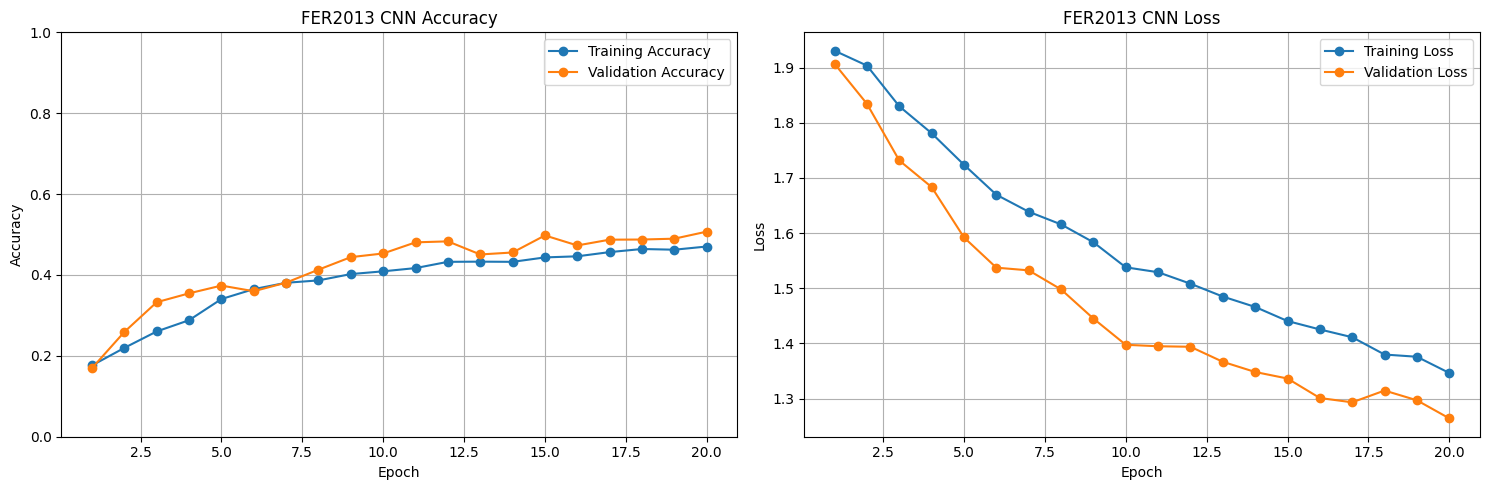

Training Accuracy: 47.04%
Validation Accuracy: 50.71%
Best Validation Accuracy: 50.71%


In [14]:
#Charts and bar graph
import matplotlib.pyplot as plt

# Check training history
assert "history" in globals(), "Run Step 7 first!"
assert len(history["train_accuracy"]) > 0, "Training history is empty!"

epochs_range = range(1, len(history["train_accuracy"]) + 1)

# Create visualization
plt.figure(figsize=(15, 5))

# =========================
# ACCURACY GRAPH
# =========================

plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    marker='o',
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_accuracy"],
    marker='o',
    label="Validation Accuracy"
)

plt.title("FER2013 CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)

# =========================
# LOSS GRAPH
# =========================

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_loss"],
    marker='o',
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker='o',
    label="Validation Loss"
)

plt.title("FER2013 CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Final results
print("Training Accuracy:",
      f"{history['train_accuracy'][-1]*100:.2f}%")

print("Validation Accuracy:",
      f"{history['val_accuracy'][-1]*100:.2f}%")

print("Best Validation Accuracy:",
      f"{best_val_accuracy*100:.2f}%")


FER2013 CNN TEST RESULTS

Test Accuracy: 50.56%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       angry       0.35      0.14      0.20       958
     disgust       0.12      0.81      0.21       111
        fear       0.26      0.08      0.13      1024
       happy       0.83      0.80      0.81      1774
     neutral       0.46      0.66      0.54      1233
         sad       0.38      0.33      0.35      1247
    surprise       0.60      0.82      0.69       831

    accuracy                           0.51      7178
   macro avg       0.43      0.52      0.42      7178
weighted avg       0.50      0.51      0.48      7178



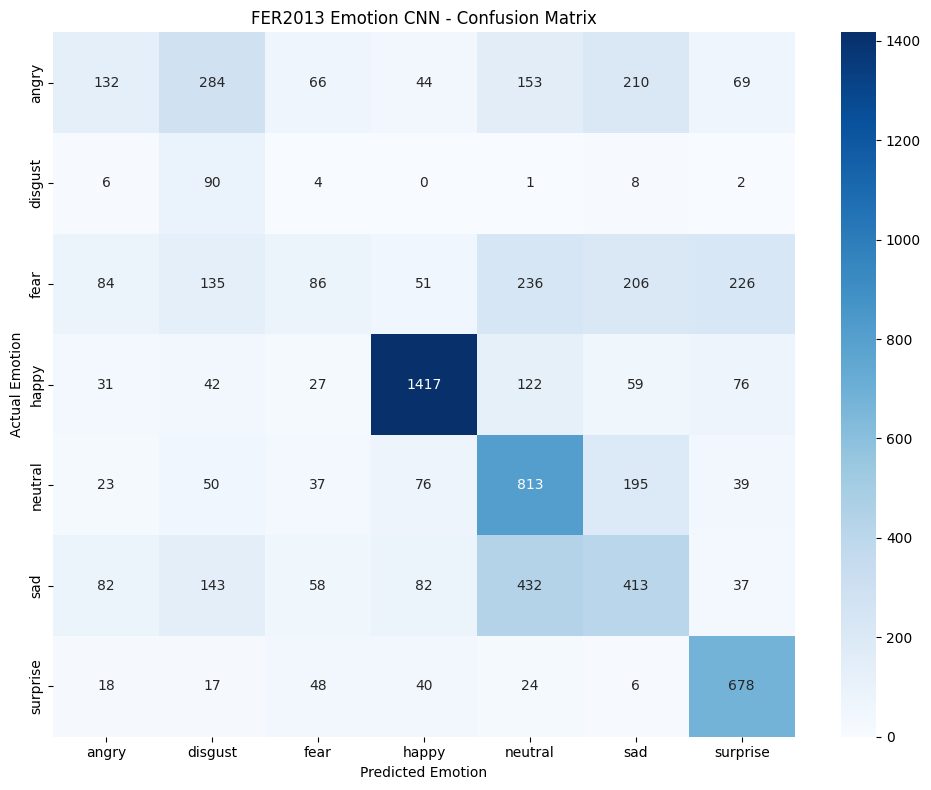


Evaluation completed successfully!


In [15]:
#Evaluation
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Evaluation mode
model.eval()

all_predictions = []
all_targets = []

# Test the CNN
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            labels.numpy()
        )

# Calculate test accuracy
test_accuracy = accuracy_score(
    all_targets,
    all_predictions
)

print("=" * 55)
print("FER2013 CNN TEST RESULTS")
print("=" * 55)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")

# Classification report
print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        all_targets,
        all_predictions,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=list(range(num_classes))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("FER2013 Emotion CNN - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()

print("\nEvaluation completed successfully!")


In [16]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [17]:

import os
import json
import torch

# Google Drive model directory
MODEL_DIR = "/content/drive/MyDrive/cognitive_mirror/video/emotion_model"

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "fer2013_emotion_model.pth"
)

LABEL_PATH = os.path.join(
    MODEL_DIR,
    "emotion_labels.json"
)

HISTORY_PATH = os.path.join(
    MODEL_DIR,
    "training_history.json"
)

INFO_PATH = os.path.join(
    MODEL_DIR,
    "model_info.json"
)

# Restore best model weights
model.load_state_dict(best_model_weights)

model.eval()

# Save model checkpoint
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": class_names,
        "num_classes": num_classes,
        "image_size": IMAGE_SIZE,
        "architecture": "EmotionCNN",
        "input_channels": 1
    },
    MODEL_PATH
)

# Save emotion labels
with open(LABEL_PATH, "w") as f:
    json.dump(class_names, f, indent=4)

# Save training history
with open(HISTORY_PATH, "w") as f:
    json.dump(history, f, indent=4)

# Save model information
model_info = {
    "model_name": "FER2013 Emotion Recognition CNN",
    "architecture": "EmotionCNN",
    "dataset": "FER2013",
    "num_classes": num_classes,
    "classes": class_names,
    "image_size": IMAGE_SIZE,
    "input_channels": 1,
    "epochs": len(history["train_accuracy"]),
    "best_validation_accuracy": float(best_val_accuracy),
    "test_accuracy": float(test_accuracy)
}

with open(INFO_PATH, "w") as f:
    json.dump(model_info, f, indent=4)

print("All files saved successfully!")
print("\nModel directory:", MODEL_DIR)

print("\nSaved files:")
print(os.listdir(MODEL_DIR))


All files saved successfully!

Model directory: /content/drive/MyDrive/cognitive_mirror/video/emotion_model

Saved files:
['fer2013_emotion_model.pth', 'emotion_labels.json', 'training_history.json', 'model_info.json']


In [18]:

import os
import torch
import json

# Check files
required_files = [
    MODEL_PATH,
    LABEL_PATH,
    HISTORY_PATH,
    INFO_PATH
]

for file_path in required_files:
    print(
        os.path.basename(file_path),
        "EXISTS" if os.path.isfile(file_path) else "MISSING"
    )

# Load checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

print("\nModel verification:")
print("Architecture:", checkpoint["architecture"])
print("Classes:", checkpoint["class_names"])
print("Number of classes:", checkpoint["num_classes"])
print("Image size:", checkpoint["image_size"])

# Test model loading
test_model = EmotionCNN(
    num_classes=checkpoint["num_classes"]
).to(DEVICE)

test_model.load_state_dict(
    checkpoint["model_state_dict"]
)

test_model.eval()

dummy = torch.randn(1, 1, 48, 48).to(DEVICE)

with torch.no_grad():
    result = test_model(dummy)

print("Output shape:", result.shape)
print("\nFER2013 CNN saved and verified successfully!")


fer2013_emotion_model.pth EXISTS
emotion_labels.json EXISTS
training_history.json EXISTS
model_info.json EXISTS

Model verification:
Architecture: EmotionCNN
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7
Image size: 48
Output shape: torch.Size([1, 7])

FER2013 CNN saved and verified successfully!
